# Energy Calculation

In [27]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
from qss.magnetization import calculate_magnetization
from qss.distributions import prepare_2D_lattice_data
from tools.scientific_plot_v2 import ScientificPlotter, PlotConfig

plotter = ScientificPlotter()

## 2D Lattice

In [29]:
N = 100
t = -1
t_prim = 0.
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Magnetization

In [30]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])
    
    if "magnetization" in mu_df.columns:
        magnetization_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        magnetization_df = calculate_magnetization(mu_df, e_k)
        magnetization_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
magnetization_df

mu  iterations  converged  \
distro n   k_BT   H_a                                              
FD     0.8 100.00 0.001000     -40.550516          23       True   
       0.9 100.00 0.001000     -20.069069          23       True   
       0.8 100.00 0.001326     -40.550516          23       True   
       0.9 100.00 0.001326     -20.069069          23       True   
       0.8 100.00 0.001758     -40.550516          23       True   
...                                   ...         ...        ...   
SSL    0.9 0.01   568.986603  -566.149489          30       True   
       0.8 0.01   754.312006  -752.448172          23       True   
       0.9 0.01   754.312006  -751.474617          29       True   
       0.8 0.01   1000.000000 -998.136157          26       True   
       0.9 0.01   1000.000000 -997.163111          28       True   

                                   residual  magnetization  
distro n   k_BT   H_a                                       
FD     0.8 100.00 0.001000     2.645846e-08       0.000005  
       0.9 100.00 0.001000     2.665464e-09       0.000005  
       0.8 100.00 0.001326     2.645483e-08       0.000006  
       0.9 100.00 0.001326     2.667338e-09       0.000007  
       0.8 100.00 0.001758     2.644844e-08       0.000008  
...                                     ...            ...  
SSL    0.9 0.01   568.986603   1.745198e-05       0.899469  
       0.8 0.01   754.312006   2.100760e-05       0.800288  
       0.9 0.01   754.312006   1.304184e-05       0.899502  
       0.8 0.01   1000.000000  2.216940e-05       0.800289  
       0.9 0.01   1000.000000  4.250658e-05       0.899443  

[2500 rows x 5 columns]

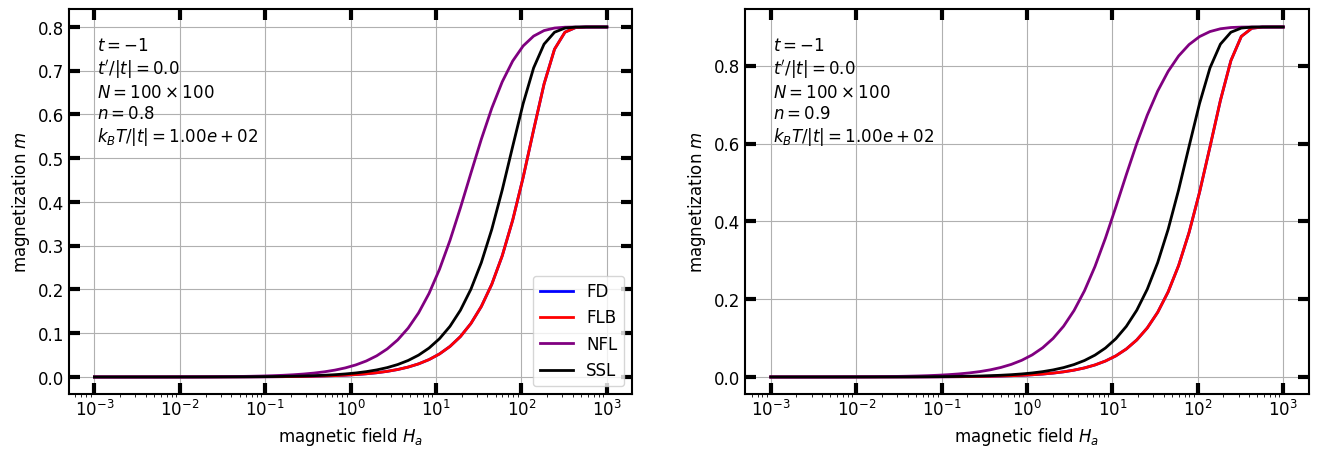

In [31]:
n_plot = n
beta_plot = 1/k_BT[-1]
distro = ["FD","FLB","NFL","SSL"]
plotter.plot_scalar_result(
    results=magnetization_df,
    x_param="H_a",
    y_col="magnetization",
    y_label=r"magnetization $m$",
    fixed_params={"beta": beta_plot},
    distros=distro,
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    t_prim=t_prim,
    N=N,
    text_pos=(0.05, 0.93),
    xscale="log",
    blue_line=True
)
plt.show()